# UAV Propeller Performance Analysis — Capstone 3

**Objective:** predict propeller performance — **thrust coefficient (CT)**, **power coefficient (CP)** and **efficiency** — from blade geometry
and operating inputs (advance ratio, RPM), using gradient boosting. A key engineered feature is **solidity** (blade area / disc area).
SQL tasks are in [`uav_propeller.sql`](uav_propeller.sql).

In [1]:
import re, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 100
DATA = "../Dataset/Capstone_3/"
SEED = 42
trapz = getattr(np, "trapezoid", None) or np.trapz      # numpy >= 2 renamed trapz -> trapezoid

## 1. Read and append the three volumes

In [2]:
exp = pd.concat([pd.read_csv(f"{DATA}experiment_vol{i}.csv").assign(volume=i) for i in (1, 2, 3)], ignore_index=True)
geom = pd.concat([pd.read_csv(f"{DATA}geom_vol{i}.csv").assign(volume=i) for i in (1, 2, 3)], ignore_index=True)
print("Experiment:", exp.shape, "| Geometry:", geom.shape)
exp.head()

Experiment: (27495, 12) | Geometry: (2316, 8)


,Propeller's Name,Blade's Name,Propeller's Brand,Number of Blades,Propeller's Diameter,Propeller's Pitch,Advanced Ratio Input,RPM Rotation Input,Thrust Coefficient Output,Power Coefficient Output,Efficiency Output,volume
0,ance 8.5x6.0 - 2,ance 8.5x6.0,ance,2,8.5,6.0,0.165,4000.0,0.0993,0.0539,0.304,1
1,ance 8.5x6.0 - 2,ance 8.5x6.0,ance,2,8.5,6.0,0.214,4000.0,0.0947,0.0543,0.374,1
2,ance 8.5x6.0 - 2,ance 8.5x6.0,ance,2,8.5,6.0,0.255,4000.0,0.0916,0.0548,0.427,1
3,ance 8.5x6.0 - 2,ance 8.5x6.0,ance,2,8.5,6.0,0.301,4000.0,0.0847,0.0540,0.473,1
4,ance 8.5x6.0 - 2,ance 8.5x6.0,ance,2,8.5,6.0,0.340,4000.0,0.0796,0.0530,0.511,1


## 2. Python-friendly variable names

In [3]:
def snake(name):
    name = name.replace("'s", "").replace("/", "_over_")
    name = re.sub(r"[^0-9a-zA-Z]+", "_", name).strip("_").lower()
    return name
exp.columns = [snake(c) for c in exp.columns]
geom.columns = [snake(c) for c in geom.columns]
geom = geom.rename(columns={"adimensional_chord_c_over_r": "c_over_r", "adimensional_radius_r_over_r": "r_over_r", "beta_angle_relative_to_rotation": "beta_deg"})
print(exp.columns.tolist()); print(geom.columns.tolist())

['propeller_name', 'blade_name', 'propeller_brand', 'number_of_blades', 'propeller_diameter', 'propeller_pitch', 'advanced_ratio_input', 'rpm_rotation_input', 'thrust_coefficient_output', 'power_coefficient_output', 'efficiency_output', 'volume']
['blade_name', 'propeller_brand', 'propeller_diameter', 'propeller_pitch', 'c_over_r', 'r_over_r', 'beta_deg', 'volume']


In [4]:
print("Duplicate experiment rows:", exp.drop(columns="volume").duplicated().sum())
print("Duplicate geometry rows:  ", geom.drop(columns="volume").duplicated().sum())
exp = exp.drop_duplicates(subset=exp.columns.drop("volume")).reset_index(drop=True)
geom = geom.drop_duplicates(subset=geom.columns.drop("volume")).reset_index(drop=True)
print("After de-duplication:", exp.shape, geom.shape)

Duplicate experiment rows: 1001
Duplicate geometry rows:   96
After de-duplication: (26494, 12) (2220, 8)


## 3. Radius and chord distributions
Blade radius `R = diameter / 2`. Then `r = (r/R)·R` and `c = (c/R)·R` (units: inches, same as the diameter).

In [5]:
geom["R"] = geom["propeller_diameter"] / 2
geom["radius"] = geom["r_over_r"] * geom["R"]
geom["chord"] = geom["c_over_r"] * geom["R"]
geom = geom.sort_values(["blade_name", "radius"]).reset_index(drop=True)
geom[["blade_name", "propeller_diameter", "R", "r_over_r", "radius", "c_over_r", "chord", "beta_deg"]].head(8)

,blade_name,propeller_diameter,R,r_over_r,radius,c_over_r,chord,beta_deg
0,apc29ff 9.0x5.0,9.0,4.5,0.15,0.675,0.160,0.7200,31.68
1,apc29ff 9.0x5.0,9.0,4.5,0.20,0.900,0.146,0.6570,34.45
2,apc29ff 9.0x5.0,9.0,4.5,0.25,1.125,0.144,0.6480,35.93
3,apc29ff 9.0x5.0,9.0,4.5,0.30,1.350,0.143,0.6435,33.33
4,apc29ff 9.0x5.0,9.0,4.5,0.35,1.575,0.143,0.6435,29.42
5,apc29ff 9.0x5.0,9.0,4.5,0.40,1.800,0.146,0.6570,26.25
6,apc29ff 9.0x5.0,9.0,4.5,0.45,2.025,0.151,0.6795,23.67
7,apc29ff 9.0x5.0,9.0,4.5,0.50,2.250,0.155,0.6975,21.65


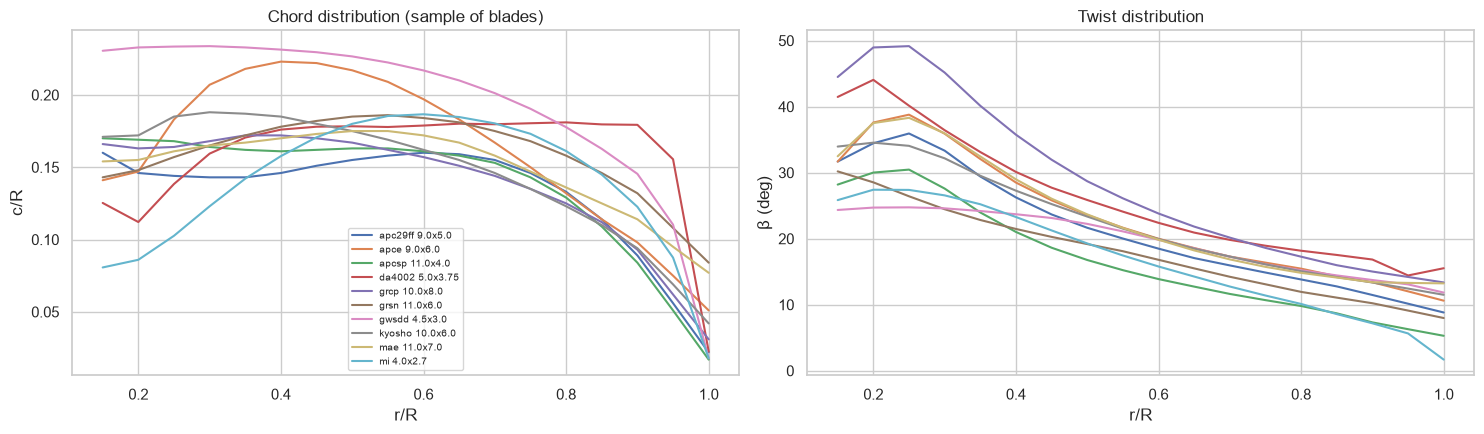

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for b in geom["blade_name"].unique()[::12]:
    g = geom[geom["blade_name"] == b]
    axes[0].plot(g["r_over_r"], g["c_over_r"], label=b); axes[1].plot(g["r_over_r"], g["beta_deg"], label=b)
axes[0].set(xlabel="r/R", ylabel="c/R", title="Chord distribution (sample of blades)"); axes[1].set(xlabel="r/R", ylabel="β (deg)", title="Twist distribution")
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 4. Blade area (trapezoidal integration) and total blade area
Area of one blade = ∫ c(r) dr from root to tip, computed with the composite trapezoidal rule (`numpy.trapz`).
Total blade area = blade area × number of blades of the propeller.

In [7]:
blade_area = geom.groupby("blade_name").apply(lambda g: trapz(g["chord"], g["radius"])).rename("blade_area")
blade_geo = geom.groupby("blade_name").agg(R=("R", "first"), n_stations=("radius", "size")).join(blade_area)
blade_geo.describe().round(3)

,R,n_stations,blade_area
count,120.000,120.000,120.000
mean,4.385,18.500,2.772
std,1.485,4.672,1.466
min,1.122,15.000,0.338
25%,4.064,18.000,1.607
50%,4.500,18.000,3.021
75%,5.500,18.000,3.639
max,9.500,54.000,9.160


In [8]:
props = exp.groupby("propeller_name").agg(blade_name=("blade_name", "first"), brand=("propeller_brand", "first"),
                                           n_blades=("number_of_blades", "first"), diameter=("propeller_diameter", "first"),
                                           pitch=("propeller_pitch", "first"), n_tests=("rpm_rotation_input", "size"))
props = props.join(blade_geo, on="blade_name")
props["total_blade_area"] = props["blade_area"] * props["n_blades"]

## 5. Disc area  A = π r²  (r = diameter / 2)

In [9]:
props["disc_area"] = np.pi * (props["diameter"] / 2) ** 2

## 6. Solidity = total blade area / disc area

In [10]:
props["solidity"] = props["total_blade_area"] / props["disc_area"]
props[["blade_name", "n_blades", "diameter", "blade_area", "total_blade_area", "disc_area", "solidity"]].dropna().sort_values("solidity").round(4)

,blade_name,n_blades,diameter,blade_area,total_blade_area,disc_area,solidity
propeller_name,,,,,,,
nr640 5x3.16 - 2,nr640 5x3.16,2,5.0,0.5374,1.0749,19.6350,0.0547
nr640 5x4.29 - 2,nr640 5x4.29,2,5.0,0.5374,1.0749,19.6350,0.0547
nr640 9x5.68 - 2,nr640 9x5.68,2,9.0,1.7413,3.4826,63.6173,0.0547
nr640 9x7.72 - 2,nr640 9x7.72,2,9.0,1.7413,3.4826,63.6173,0.0547
apce 19.0x12.0 - 2,apce 19.0x12.0,2,19.0,9.1604,18.3208,283.5287,0.0646
...,...,...,...,...,...,...,...
da4052 5.0x3.75 - 3,da4052 5.0x3.75,3,5.0,1.2031,3.6093,19.6350,0.1838
da4052 9.0x6.75 - 3,da4052 9.0x6.75,3,9.0,3.9458,11.8373,63.6173,0.1861
da4022 9.0x6.75 - 4,da4022 9.0x6.75,4,9.0,3.6367,14.5470,63.6173,0.2287


## 7. Collate solidity with the experiment data

In [11]:
exp = exp.merge(props[["solidity", "blade_area", "total_blade_area", "disc_area"]], left_on="propeller_name", right_index=True, how="left")
exp[["propeller_name", "number_of_blades", "advanced_ratio_input", "rpm_rotation_input", "solidity",
     "thrust_coefficient_output", "power_coefficient_output", "efficiency_output"]].head()

,propeller_name,number_of_blades,advanced_ratio_input,rpm_rotation_input,solidity,thrust_coefficient_output,power_coefficient_output,efficiency_output
0,ance 8.5x6.0 - 2,2,0.165,4000.0,NaN,0.0993,0.0539,0.304
1,ance 8.5x6.0 - 2,2,0.214,4000.0,NaN,0.0947,0.0543,0.374
2,ance 8.5x6.0 - 2,2,0.255,4000.0,NaN,0.0916,0.0548,0.427
3,ance 8.5x6.0 - 2,2,0.301,4000.0,NaN,0.0847,0.0540,0.473
4,ance 8.5x6.0 - 2,2,0.340,4000.0,NaN,0.0796,0.0530,0.511


## 8. Could solidity be calculated for every propeller?

Propellers with solidity: 134 of 240 (56%)
Experiment rows with solidity: 54%


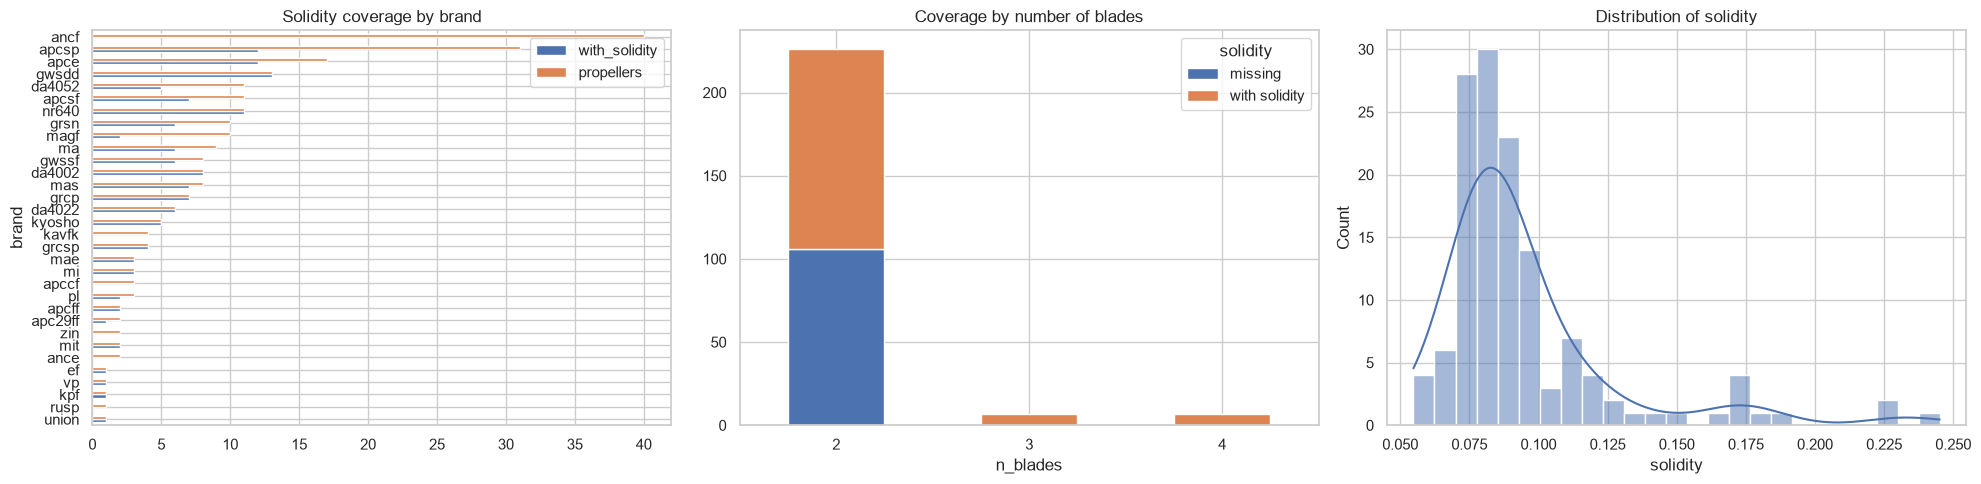

,with_solidity,propellers,coverage_%
brand,,,
ance,0,2,0.0
rusp,0,1,0.0
kavfk,0,4,0.0
zin,0,2,0.0
ancf,0,40,0.0
apccf,0,3,0.0
magf,2,10,20.0
apcsp,12,31,39.0
da4052,5,11,45.0


In [12]:
has_sol = props["solidity"].notna()
print(f"Propellers with solidity: {has_sol.sum()} of {len(props)} ({has_sol.mean():.0%})")
print(f"Experiment rows with solidity: {exp['solidity'].notna().mean():.0%}")
cov = props.assign(has_solidity=has_sol).groupby("brand")["has_solidity"].agg(["sum", "size"]).rename(columns={"sum": "with_solidity", "size": "propellers"})
cov["coverage_%"] = (cov["with_solidity"] / cov["propellers"] * 100).round(0)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
cov.sort_values("propellers")[["with_solidity", "propellers"]].plot.barh(ax=axes[0]); axes[0].set_title("Solidity coverage by brand")
pd.crosstab(props["n_blades"], has_sol).rename(columns={True: "with solidity", False: "missing"}).plot.bar(stacked=True, ax=axes[1], rot=0)
axes[1].set_title("Coverage by number of blades")
sns.histplot(props["solidity"].dropna(), bins=25, kde=True, ax=axes[2]); axes[2].set_title("Distribution of solidity")
plt.tight_layout(); plt.show()
cov.sort_values("coverage_%")

**Findings:** geometry files cover only **120 of the 226 blade designs**, so solidity can be computed for **134 of 240 propellers (56%)**,
covering about **54% of experiment rows**. Coverage depends heavily on brand — `ancf` (40 propellers), `kavfk`, `apccf` and others have no
geometry at all. **All 3- and 4-blade propellers do have geometry.** Solidity ranges from ~0.055 to ~0.17 for 2-blade propellers and rises to
~0.08-0.25 for 3/4-blade propellers (more blades → more blade area). A few blade names look like data-entry errors (e.g. `ancf 125.0x9.0`,
a 125-inch diameter).

## 9. Bivariate analysis

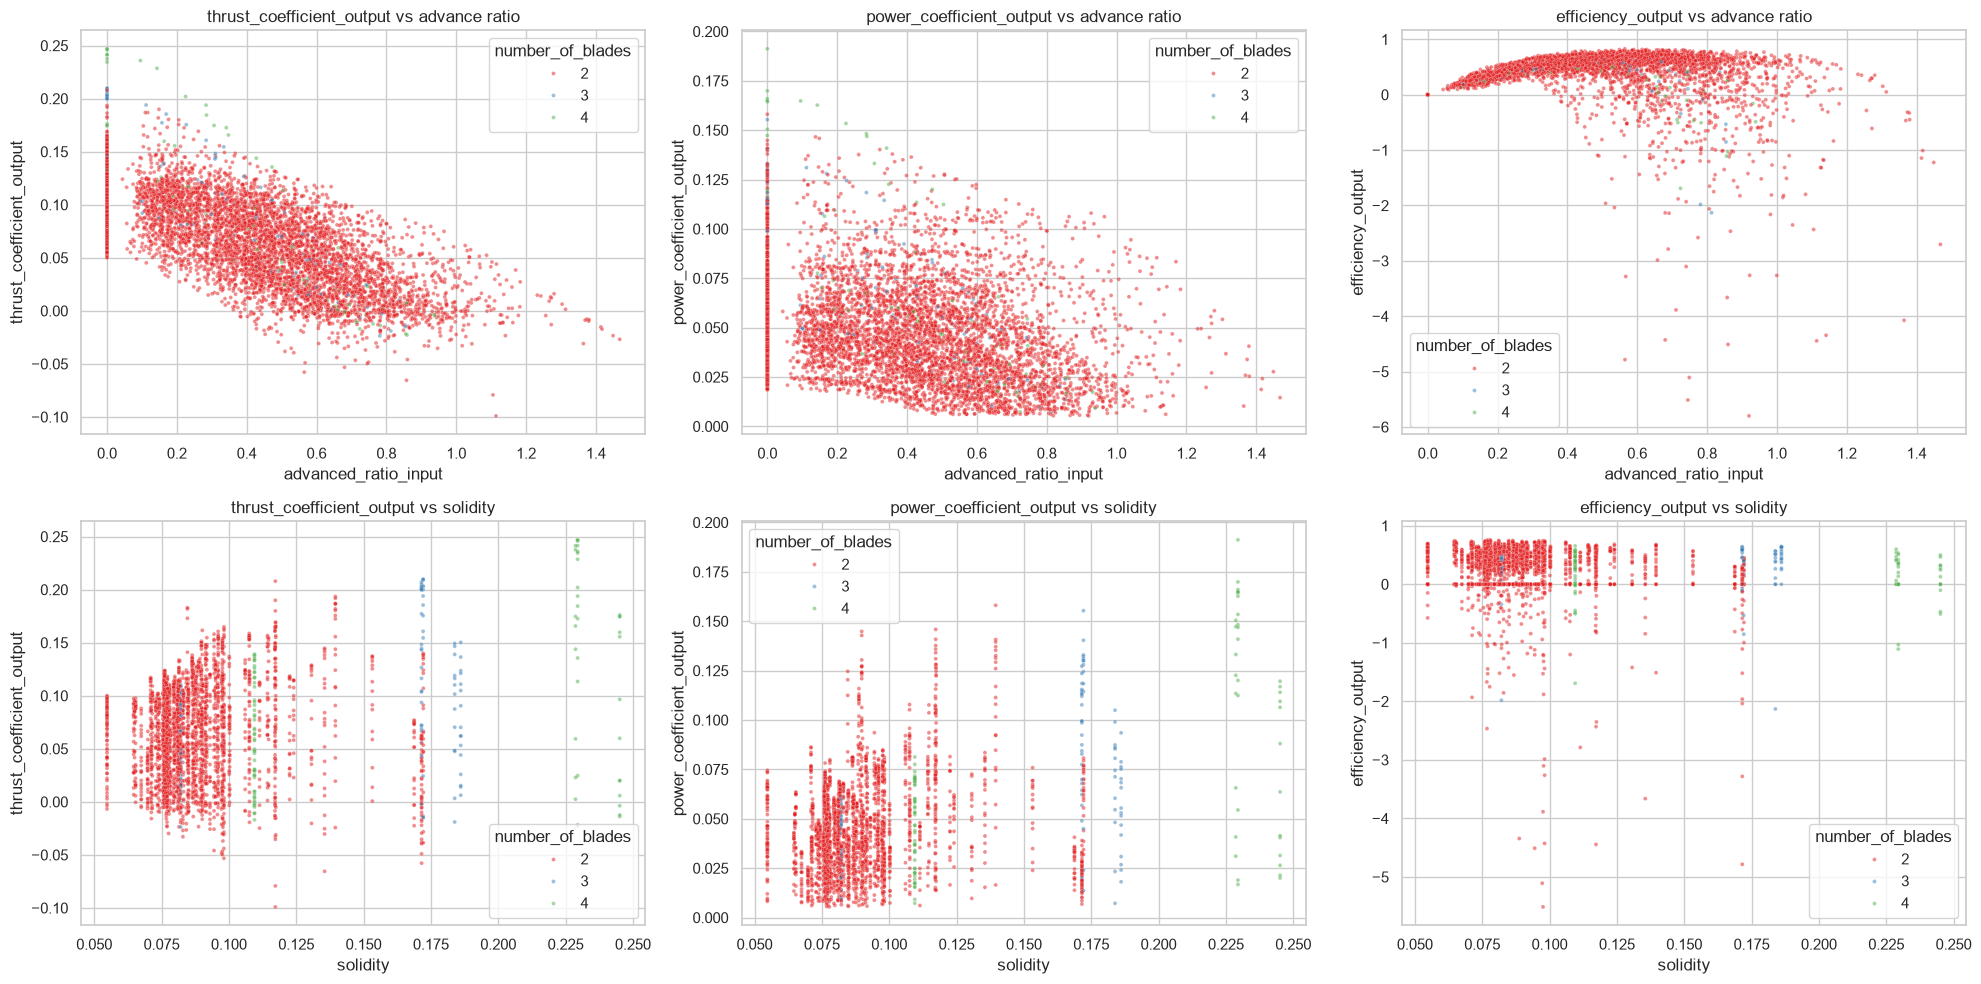

In [13]:
targets = ["thrust_coefficient_output", "power_coefficient_output", "efficiency_output"]
smp = exp.sample(6000, random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for i, t in enumerate(targets):
    sns.scatterplot(data=smp, x="advanced_ratio_input", y=t, hue="number_of_blades", palette="Set1", s=8, alpha=0.5, ax=axes[0, i])
    axes[0, i].set_title(f"{t} vs advance ratio")
    sns.scatterplot(data=smp, x="solidity", y=t, hue="number_of_blades", palette="Set1", s=8, alpha=0.5, ax=axes[1, i])
    axes[1, i].set_title(f"{t} vs solidity")
plt.tight_layout(); plt.show()

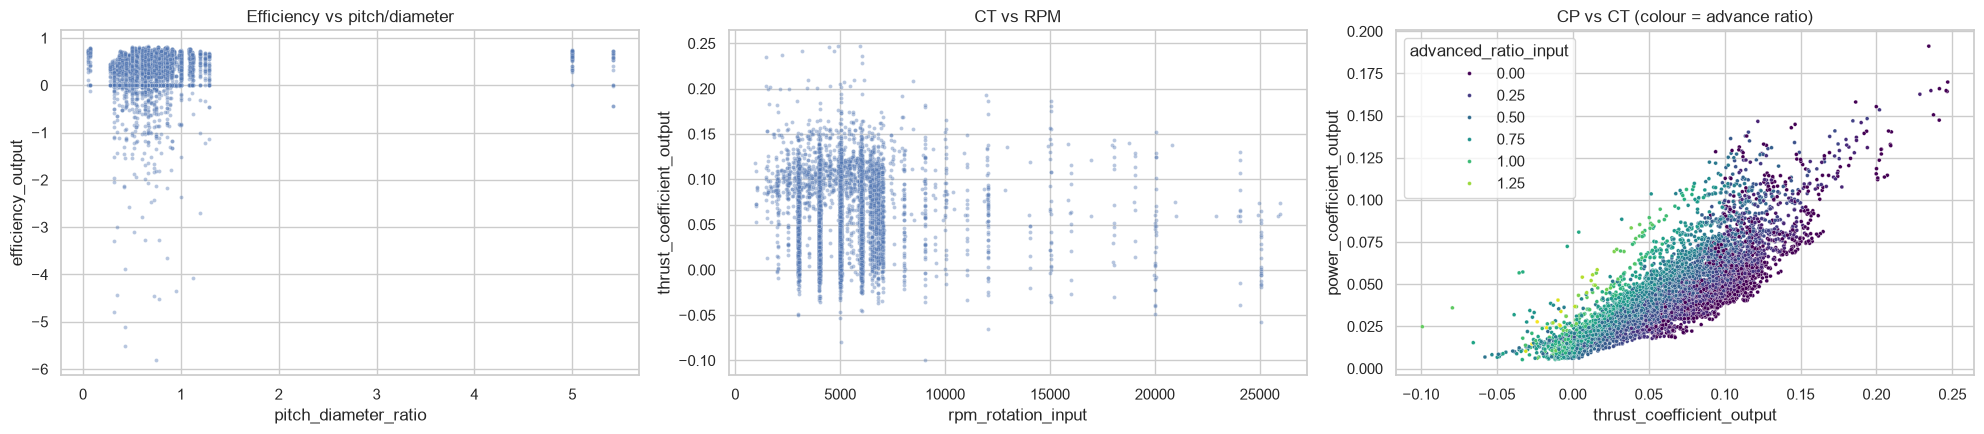

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
smp["pitch_diameter_ratio"] = smp["propeller_pitch"] / smp["propeller_diameter"]
sns.scatterplot(data=smp, x="pitch_diameter_ratio", y="efficiency_output", s=8, alpha=0.4, ax=axes[0]); axes[0].set_title("Efficiency vs pitch/diameter")
sns.scatterplot(data=smp, x="rpm_rotation_input", y="thrust_coefficient_output", s=8, alpha=0.4, ax=axes[1]); axes[1].set_title("CT vs RPM")
sns.scatterplot(data=smp, x="thrust_coefficient_output", y="power_coefficient_output", hue="advanced_ratio_input", s=8, ax=axes[2], palette="viridis")
axes[2].set_title("CP vs CT (colour = advance ratio)")
plt.tight_layout(); plt.show()

**Observations**
* **Advance ratio is the dominant input:** CT and CP fall almost linearly as J increases, while efficiency rises to a peak (~0.6-0.85) and then drops
  sharply when thrust approaches zero (negative efficiency = windmilling region).
* **Higher solidity → higher CT and CP** (more blade area produces more thrust and absorbs more power), but not higher efficiency.
* **Higher pitch/diameter** shifts the efficiency peak to higher advance ratios; RPM has only a small effect on the coefficients (they are non-dimensional).

## 10. Correlation heatmap

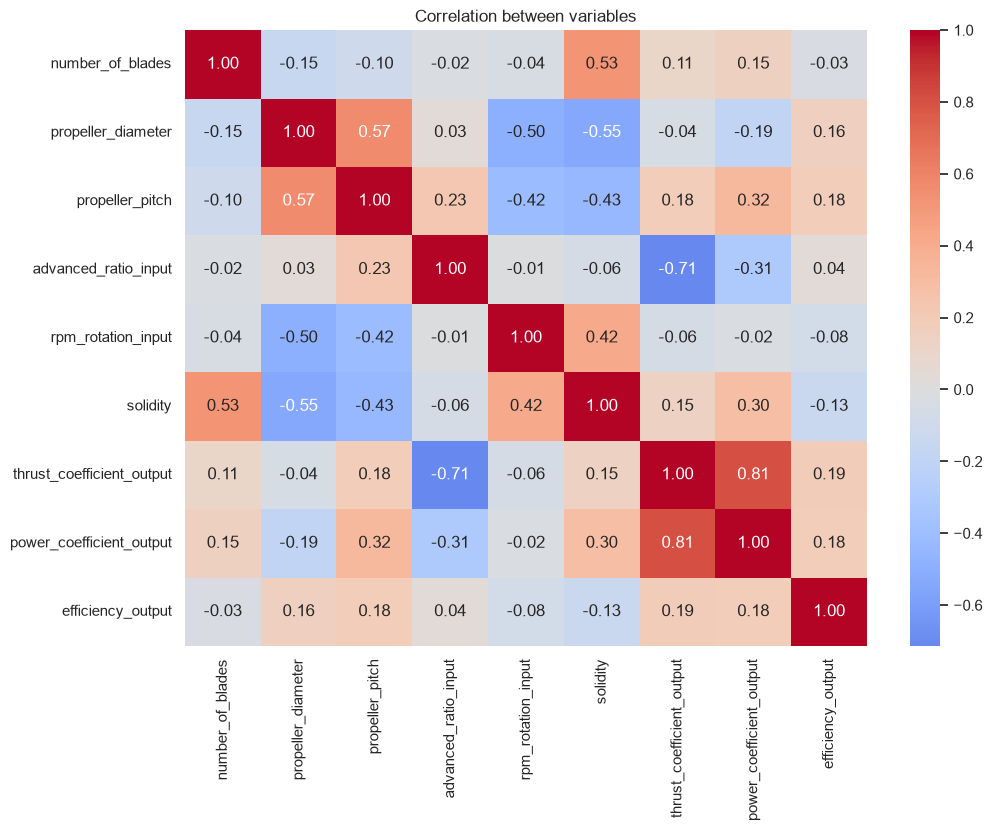

In [15]:
corr_cols = ["number_of_blades", "propeller_diameter", "propeller_pitch", "advanced_ratio_input", "rpm_rotation_input", "solidity"] + targets
plt.figure(figsize=(11, 8))
sns.heatmap(exp[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between variables"); plt.show()

## 11. Missing values & treatment

In [16]:
print(exp.isna().sum()[lambda s: s > 0])

solidity            12296
blade_area          12296
total_blade_area    12296
dtype: int64


Only the engineered geometry columns (solidity, areas) are missing — for propellers without geometry files (all of them 2-blade).
Treatment: impute solidity with a **gradient boosting model trained on propellers that have geometry**, predicting solidity from brand,
number of blades, diameter and pitch (propellers of the same family tend to have similar blade shapes). Its accuracy is compared with simple median imputation below.

In [17]:
from sklearn.model_selection import cross_val_score
sol_feats = ["number_of_blades", "propeller_diameter", "propeller_pitch", "brand_code"]
props_m = props.reset_index().rename(columns={"n_blades": "number_of_blades", "diameter": "propeller_diameter", "pitch": "propeller_pitch"})
props_m["brand_code"] = props_m["brand"].astype("category").cat.codes
known = props_m[props_m["solidity"].notna()]
sol_model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, categorical_features=[3], random_state=SEED)
cv = cross_val_score(sol_model, known[sol_feats], known["solidity"], cv=5, scoring="neg_mean_absolute_error")
print(f"Solidity imputation model CV MAE: {-cv.mean():.4f} (mean solidity {known['solidity'].mean():.4f}; median-imputation MAE {np.abs(known['solidity'] - known['solidity'].median()).mean():.4f})")
sol_model.fit(known[sol_feats], known["solidity"])
props_m["solidity_imputed"] = props_m["solidity"].fillna(pd.Series(sol_model.predict(props_m[sol_feats]), index=props_m.index))
exp = exp.merge(props_m[["propeller_name", "solidity_imputed", "brand_code"]], on="propeller_name", how="left")
print("Missing after imputation:", exp["solidity_imputed"].isna().sum())

Solidity imputation model CV MAE: 0.0189 (mean solidity 0.0953; median-imputation MAE 0.0194)


Missing after imputation: 0


## 12. Predictive models (Gradient Boosting)
* **Train** on propellers with **2 blades**; **evaluate** on propellers with **3 and 4 blades** (an out-of-distribution test).
  Because all 3/4-blade propellers have geometry, the test set is identical for every model, so the comparison is fair.
* Three variants per target:
  1. **Without imputation** — solidity left missing (`HistGradientBoostingRegressor` handles NaN natively).
  2. **With imputation** — imputed solidity.
  3. **Without solidity** — geometry information excluded.

In [18]:
base_feats = ["advanced_ratio_input", "rpm_rotation_input", "propeller_diameter", "propeller_pitch", "number_of_blades"]
variants = {"1. Without imputation": base_feats + ["solidity"],
            "2. With imputation": base_feats + ["solidity_imputed"],
            "3. Without solidity": base_feats}
train = exp[exp["number_of_blades"] == 2]
test = exp[exp["number_of_blades"] > 2]
print("Train rows (2 blades):", len(train), "| Test rows (3-4 blades):", len(test))

rows, preds = [], {}
for t in targets:
    for vname, feats in variants.items():
        m = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_leaf_nodes=31, random_state=SEED)
        m.fit(train[feats], train[t])
        p_tr, p_te = m.predict(train[feats]), m.predict(test[feats])
        preds[(t, vname)] = p_te
        rows.append({"target": t, "model": vname, "train_r2": r2_score(train[t], p_tr), "test_r2": r2_score(test[t], p_te),
                     "test_mae": mean_absolute_error(test[t], p_te), "test_rmse": np.sqrt(mean_squared_error(test[t], p_te))})
perf = pd.DataFrame(rows)
perf.pivot(index="model", columns="target", values="test_r2").round(4)

Train rows (2 blades): 25614 | Test rows (3-4 blades): 880


target,efficiency_output,power_coefficient_output,thrust_coefficient_output
model,,,
1. Without imputation,0.2650,0.3862,0.6298
2. With imputation,0.2499,0.3415,0.6506
3. Without solidity,0.4989,0.4365,0.6624


In [19]:
perf.round(4)

,target,model,train_r2,test_r2,test_mae,test_rmse
0,thrust_coefficient_output,1. Without imputation,0.9850,0.6298,0.0287,0.0409
1,thrust_coefficient_output,2. With imputation,0.9884,0.6506,0.0272,0.0397
2,thrust_coefficient_output,3. Without solidity,0.9620,0.6624,0.0268,0.0390
3,power_coefficient_output,1. Without imputation,0.9799,0.3862,0.0222,0.0309
4,power_coefficient_output,2. With imputation,0.9833,0.3415,0.0231,0.0320
5,power_coefficient_output,3. Without solidity,0.9531,0.4365,0.0212,0.0296
6,efficiency_output,1. Without imputation,0.8393,0.2650,0.1795,0.3541
7,efficiency_output,2. With imputation,0.8426,0.2499,0.1708,0.3577
8,efficiency_output,3. Without solidity,0.7847,0.4989,0.1054,0.2924


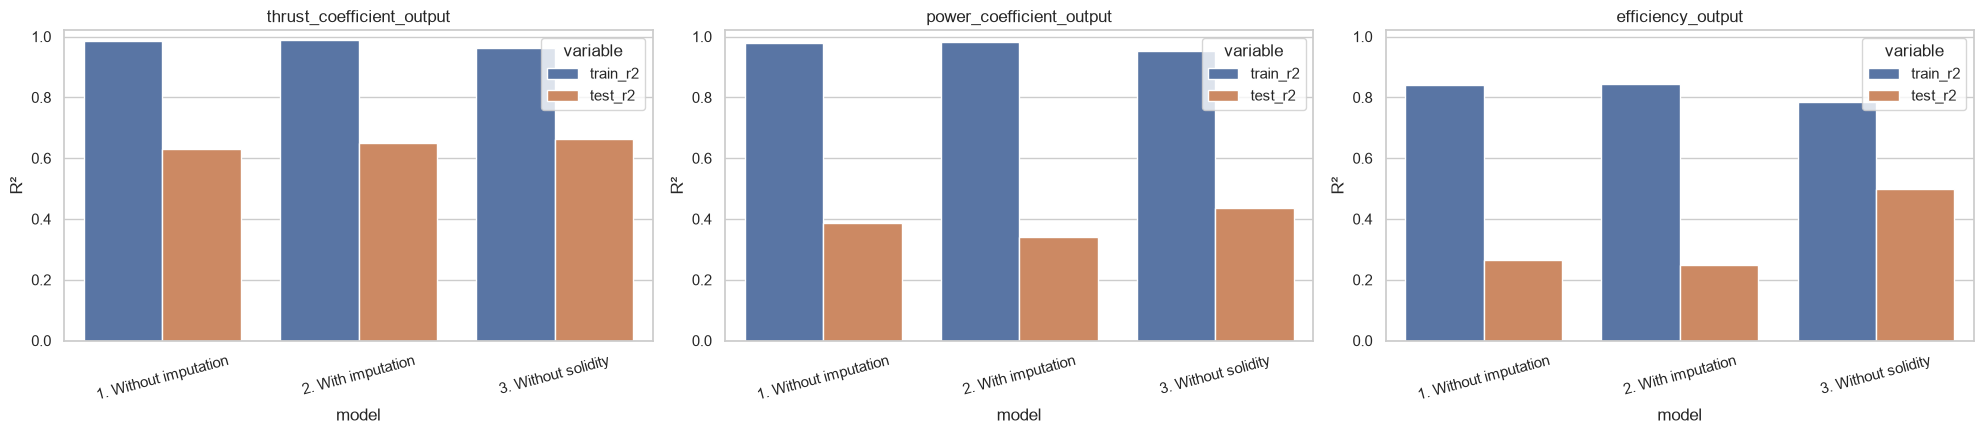

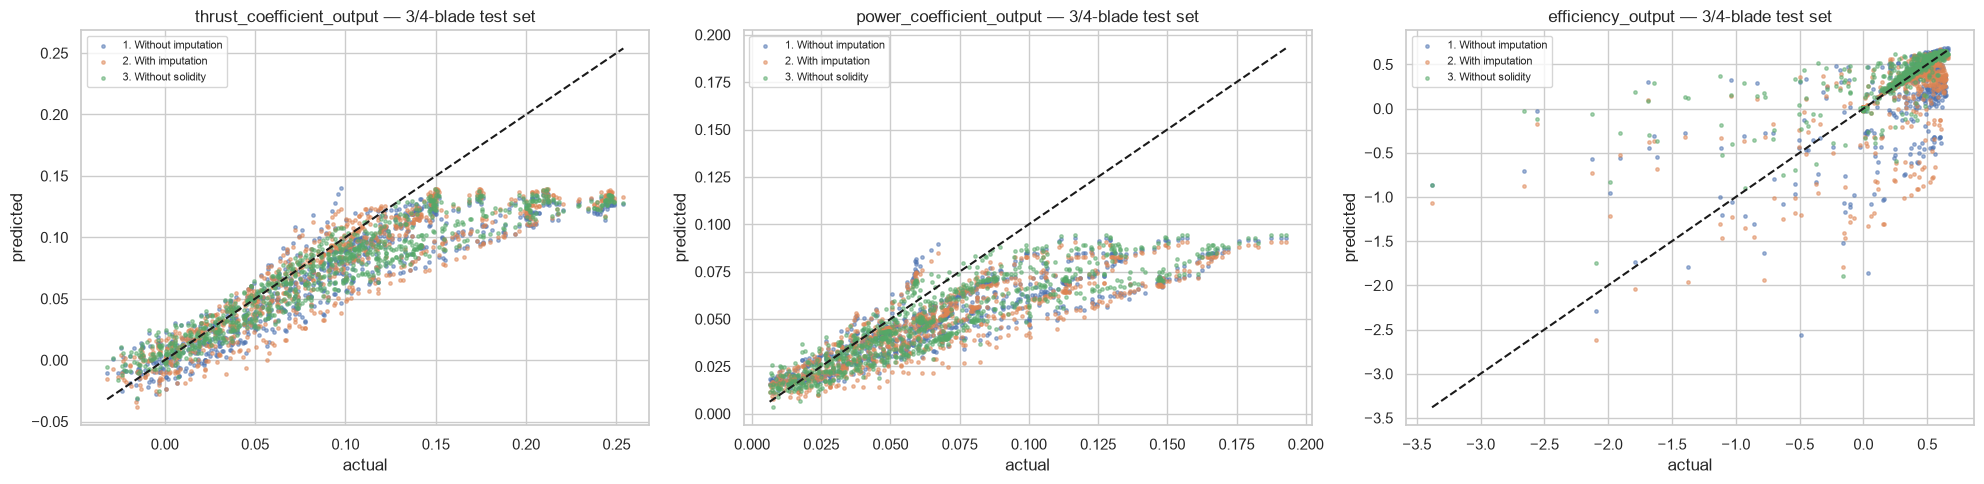

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
for ax, t in zip(axes, targets):
    sub = perf[perf["target"] == t]
    sns.barplot(data=sub.melt(id_vars="model", value_vars=["train_r2", "test_r2"]), x="model", y="value", hue="variable", ax=ax)
    ax.set_title(t); ax.set_ylabel("R²"); ax.tick_params(axis="x", rotation=15); ax.set_ylim(min(0, sub["test_r2"].min() - 0.05), 1.02)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, t in zip(axes, targets):
    for vname in variants:
        ax.scatter(test[t], preds[(t, vname)], s=6, alpha=0.5, label=vname)
    lim = [test[t].min(), test[t].max()]; ax.plot(lim, lim, "k--")
    ax.set(xlabel="actual", ylabel="predicted", title=f"{t} — 3/4-blade test set"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Conclusions
* **Solidity coverage:** solidity could be computed for 56% of propellers; missing geometry is concentrated in a few brands and only affects 2-blade propellers.
  The model-based imputation is only marginally better than the median (MAE 0.0189 vs 0.0194), because brand and dimensions explain little of the
  variation in blade shape — imputed values should be treated as rough estimates.
* **Model comparison (train on 2 blades, test on 3-4 blades):** the model **without solidity generalises best** (test R²: CT ≈ 0.66, CP ≈ 0.44,
  efficiency ≈ 0.50). Adding solidity — imputed or not — fits the training data better but *lowers* test R², especially for efficiency.
* **Why:** 3/4-blade propellers have solidity values (median ≈ 0.17, up to 0.25) mostly **outside the range seen in training** (2-blade median ≈ 0.08,
  max ≈ 0.17). Tree-based gradient boosting cannot extrapolate beyond its training range, so it treats these propellers like the few unusual
  high-solidity 2-blade designs. Solidity is physically important (it raises CT and CP), but this train/test design exposes the extrapolation limit.
* **Recommendations:** to use solidity effectively, include some 3/4-blade data in training, or use a model that can extrapolate (e.g. a
  physics-informed or linear term in solidity combined with boosting on residuals). Advance ratio remains the dominant driver of all three outputs.